<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/Airline_Passenger_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset

# Load the classic Airline Passengers dataset
airline_data = get_rdataset(
    "AirPassengers",
    "datasets"
).data

dates = pd.date_range(
    start="1949-01-01",
    periods=len(airline_data),
    freq="MS"
)

series = pd.Series(
    airline_data["value"].values,
    index=dates,
    name="Passengers"
)

# Inspect the dataset
print("Number of observations:", len(series))
print("\nFirst 5 observations:")
print(series.head())

print("\nLast 5 observations:")
print(series.tail())

print("\nData type:", series.dtype)
print("Missing values:", series.isna().sum())
print("Duplicate timestamps:", series.index.duplicated().sum())
print("Frequency:", series.index.freq)
print("Date range:", series.index.min(), "to", series.index.max())

print("\nDescriptive statistics:")
print(series.describe())


Number of observations: 144

First 5 observations:
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

Last 5 observations:
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64

Data type: int64
Missing values: 0
Duplicate timestamps: 0
Frequency: <MonthBegin>
Date range: 1949-01-01 00:00:00 to 1960-12-01 00:00:00

Descriptive statistics:
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Passengers, dtype: float64


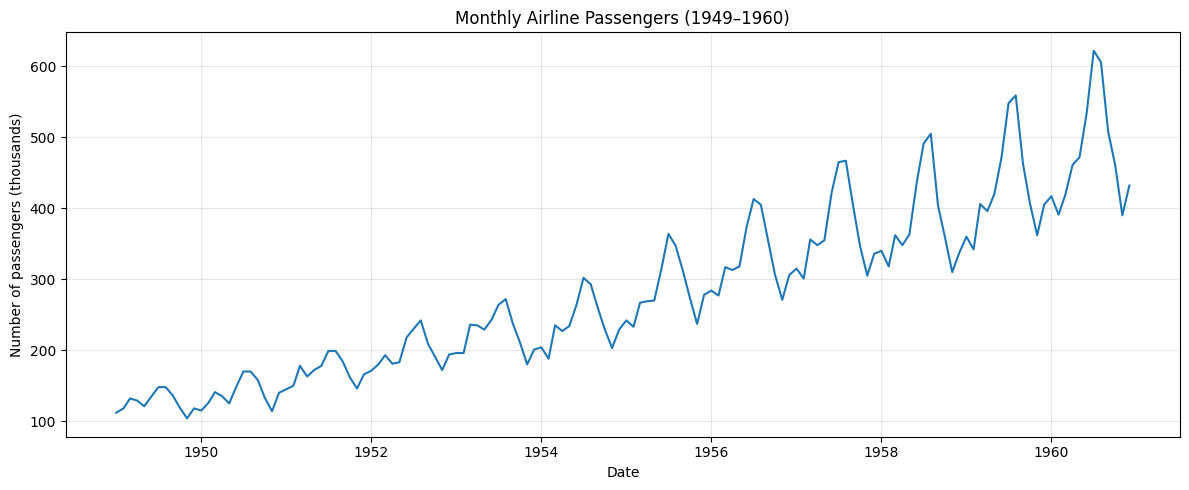

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(series.index, series.values)

plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Date")
plt.ylabel("Number of passengers (thousands)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

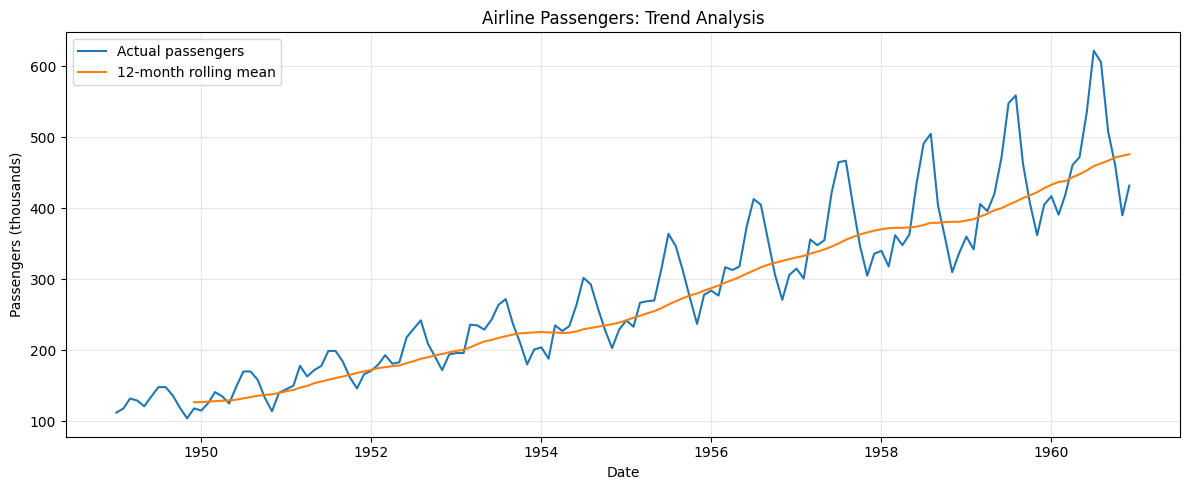

In [ ]:
import matplotlib.pyplot as plt

# Original series and 12-month rolling mean
rolling_mean = series.rolling(window=12).mean()

plt.figure(figsize=(12, 5))

plt.plot(series, label="Actual passengers")
plt.plot(rolling_mean, label="12-month rolling mean")

plt.title("Airline Passengers: Trend Analysis")
plt.xlabel("Date")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


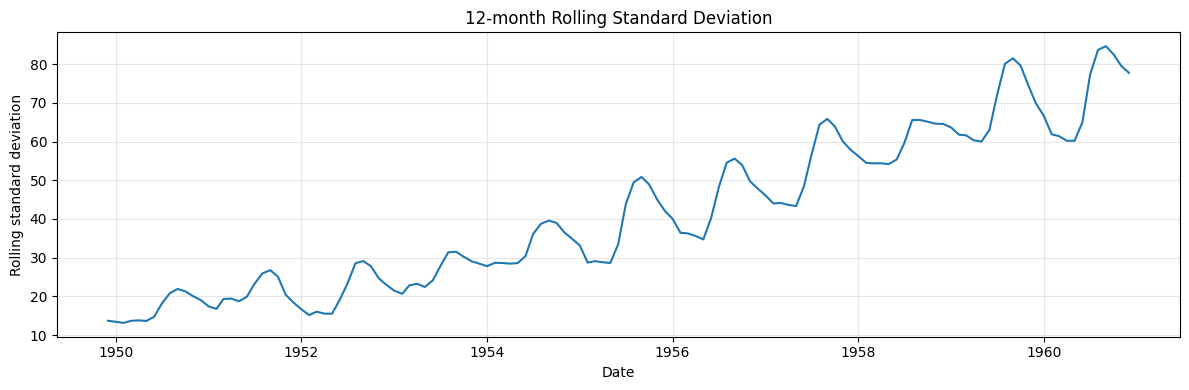

In [ ]:
rolling_std = series.rolling(window=12).std()

plt.figure(figsize=(12, 4))
plt.plot(rolling_std)

plt.title("12-month Rolling Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Rolling standard deviation")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Jan    241.75
Feb    235.00
Mar    270.17
Apr    267.08
May    271.83
Jun    311.67
Jul    351.33
Aug    351.08
Sep    302.42
Oct    266.58
Nov    232.83
Dec    261.83
Name: Passengers, dtype: float64


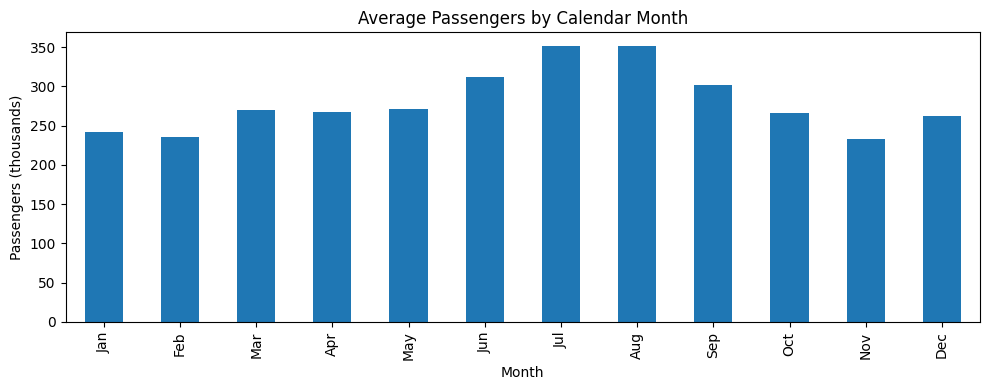

In [ ]:
monthly_average = series.groupby(series.index.month).mean()

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_average.index = month_names

print(monthly_average.round(2))

monthly_average.plot(
    kind="bar",
    figsize=(10, 4),
    title="Average Passengers by Calendar Month"
)

plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.tight_layout()
plt.show()


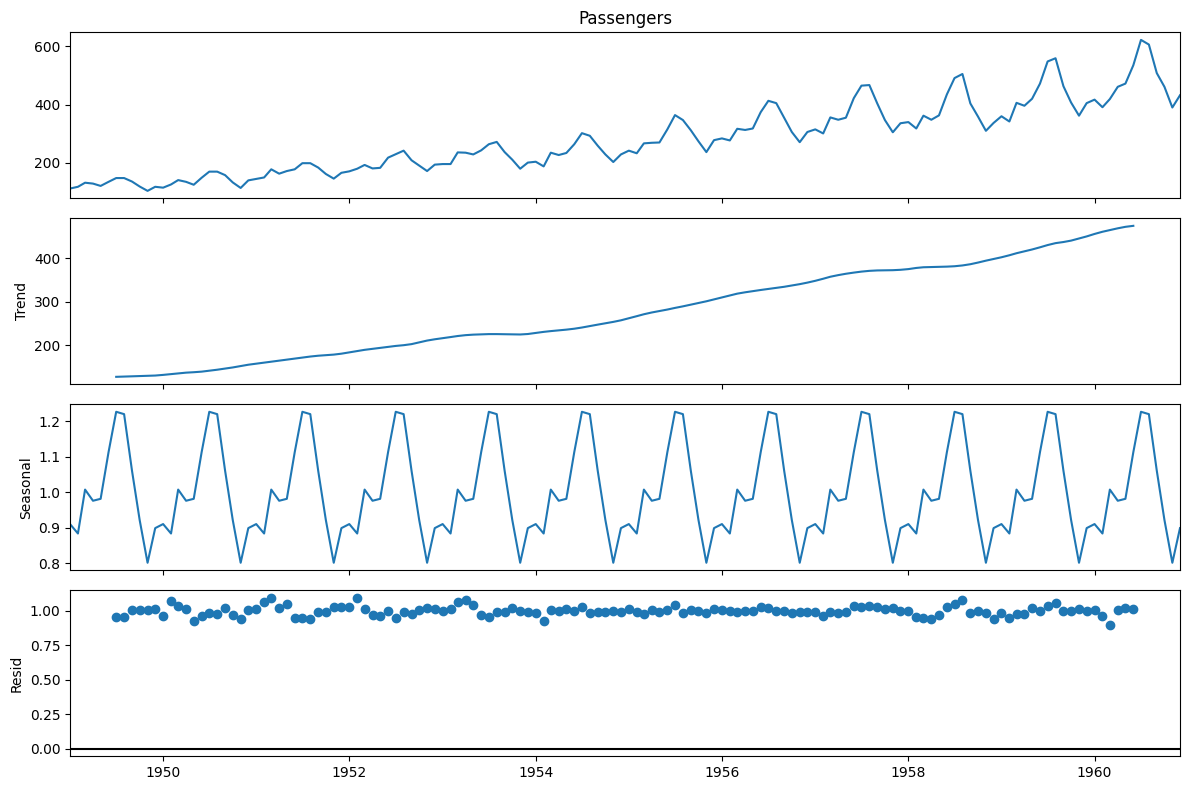

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    series,
    model="multiplicative",
    period=12
)

decomposition.plot()
plt.gcf().set_size_inches(12, 8)
plt.tight_layout()
plt.show()


In [ ]:
test_size = 12

train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())
print("Training observations:", len(train))
print("Testing observations:", len(test))

Training period: 1949-01-01 00:00:00 to 1959-12-01 00:00:00
Testing period: 1960-01-01 00:00:00 to 1960-12-01 00:00:00
Training observations: 132
Testing observations: 12


In [ ]:
naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index,
    name="Naive Forecast"
)

print(naive_forecast)

1960-01-01    405
1960-02-01    405
1960-03-01    405
1960-04-01    405
1960-05-01    405
1960-06-01    405
1960-07-01    405
1960-08-01    405
1960-09-01    405
1960-10-01    405
1960-11-01    405
1960-12-01    405
Freq: MS, Name: Naive Forecast, dtype: int64


In [ ]:
moving_average_forecast = pd.Series(
    train.iloc[-12:].mean(),
    index=test.index,
    name="Moving Average Forecast"
)

print(moving_average_forecast)

1960-01-01    428.333333
1960-02-01    428.333333
1960-03-01    428.333333
1960-04-01    428.333333
1960-05-01    428.333333
1960-06-01    428.333333
1960-07-01    428.333333
1960-08-01    428.333333
1960-09-01    428.333333
1960-10-01    428.333333
1960-11-01    428.333333
1960-12-01    428.333333
Freq: MS, Name: Moving Average Forecast, dtype: float64


In [ ]:
seasonal_naive_forecast = pd.Series(
    train.iloc[-12:].to_numpy(),
    index=test.index,
    name="Seasonal Naive Forecast"
)

print(seasonal_naive_forecast)

1960-01-01    360
1960-02-01    342
1960-03-01    406
1960-04-01    396
1960-05-01    420
1960-06-01    472
1960-07-01    548
1960-08-01    559
1960-09-01    463
1960-10-01    407
1960-11-01    362
1960-12-01    405
Freq: MS, Name: Seasonal Naive Forecast, dtype: int64


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

def forecast_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = mean_squared_error(actual, predicted) ** 0.5
    mape = mean_absolute_percentage_error(actual, predicted) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

forecasts = {
    "Naive": naive_forecast,
    "Moving Average": moving_average_forecast,
    "Seasonal Naive": seasonal_naive_forecast
}

results = pd.DataFrame({
    name: forecast_metrics(test, forecast)
    for name, forecast in forecasts.items()
}).T

print(results.round(2))

                  MAE    RMSE  MAPE (%)
Naive           76.00  102.98     14.25
Moving Average  63.89   88.47     12.06
Seasonal Naive  47.83   50.71      9.99


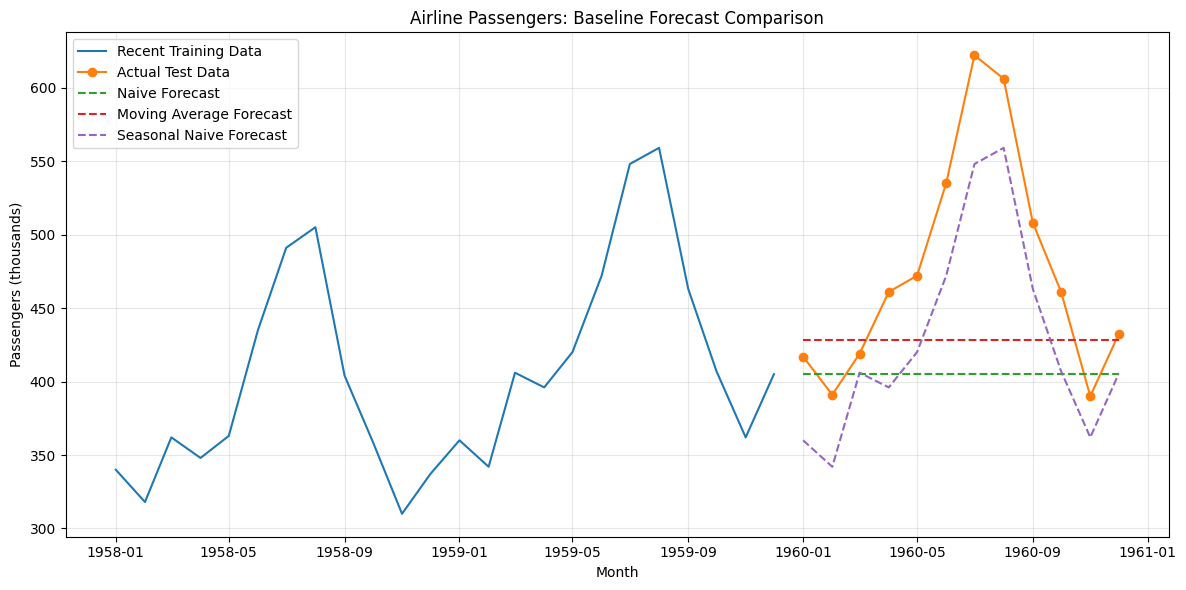

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(train.index[-24:], train.iloc[-24:],
         label="Recent Training Data")
plt.plot(test.index, test,
         label="Actual Test Data", marker="o")
plt.plot(test.index, naive_forecast,
         label="Naive Forecast", linestyle="--")
plt.plot(test.index, moving_average_forecast,
         label="Moving Average Forecast", linestyle="--")
plt.plot(test.index, seasonal_naive_forecast,
         label="Seasonal Naive Forecast", linestyle="--")

plt.title("Airline Passengers: Baseline Forecast Comparison")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

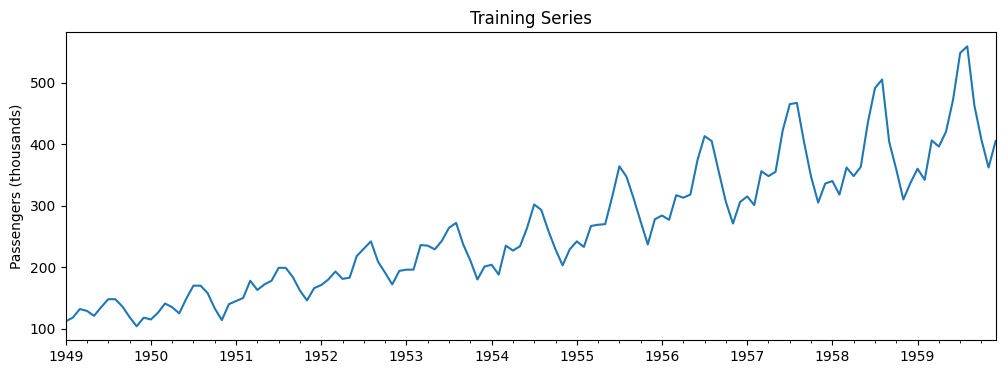

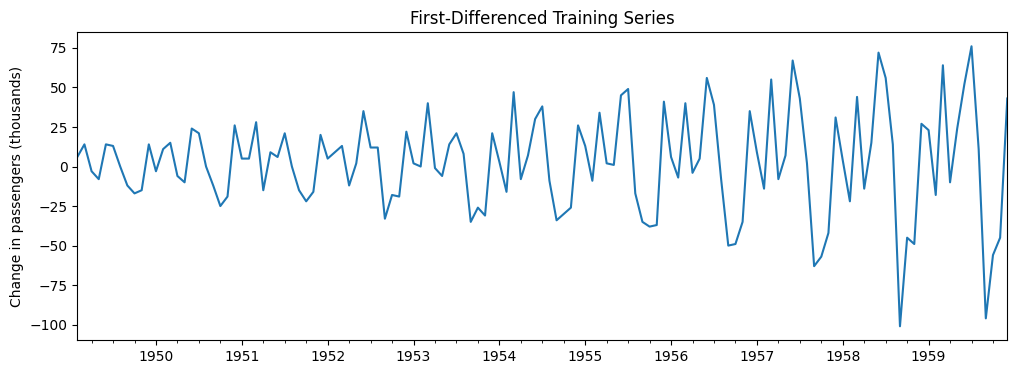

In [ ]:
import matplotlib.pyplot as plt

train.plot(figsize=(12, 4), title="Training Series")
plt.ylabel("Passengers (thousands)")
plt.show()

train_diff = train.diff().dropna()

train_diff.plot(figsize=(12, 4), title="First-Differenced Training Series")
plt.ylabel("Change in passengers (thousands)")
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train.dropna())

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF statistic: 0.8880265130074991
p-value: 0.9929320626482829


/tmp/ipykernel_1151/3816069661.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train.dropna())


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(
    train,
    order=(2, 1, 1)
).fit()

arima_forecast = arima_model.forecast(steps=len(test))
arima_forecast.index = test.index

print(arima_model.summary())
print(arima_forecast)

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  132
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -619.131
Date:                Mon, 19 Oct 2026   AIC                           1246.262
Time:                        08:59:25   BIC                           1257.763
Sample:                    01-01-1949   HQIC                          1250.936
                         - 12-01-1959                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0698      0.094     11.323      0.000       0.885       1.255
ar.L2         -0.4734      0.101     -4.670      0.000      -0.672      -0.275
ma.L1         -0.8402      0.085     -9.851      0.0

In [ ]:
forecasts["ARIMA(2,1,1)"] = arima_forecast

results = pd.DataFrame({
    name: forecast_metrics(test, forecast)
    for name, forecast in forecasts.items()
}).T

print(results.round(2))

                  MAE    RMSE  MAPE (%)
Naive           76.00  102.98     14.25
Moving Average  63.89   88.47     12.06
Seasonal Naive  47.83   50.71      9.99
ARIMA(2,1,1)    65.23   87.88     12.54


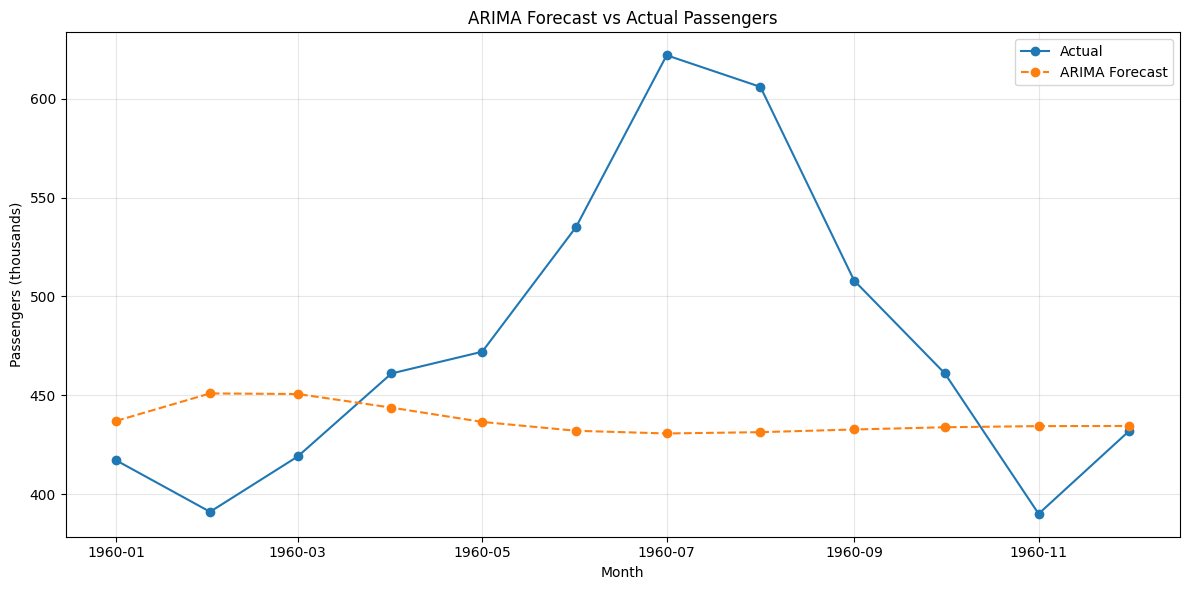

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(test.index, test, label="Actual", marker="o")
plt.plot(arima_forecast.index, arima_forecast,
         label="ARIMA Forecast", linestyle="--", marker="o")

plt.title("ARIMA Forecast vs Actual Passengers")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

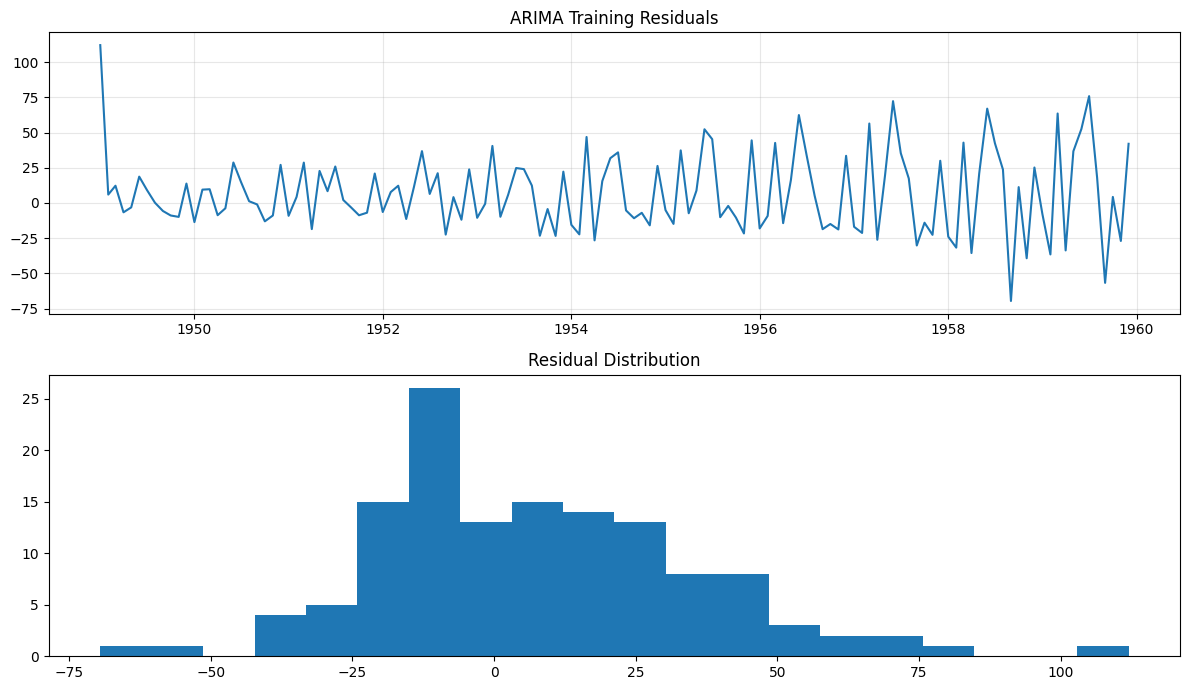

In [ ]:
residuals = arima_model.resid

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(residuals)
axes[0].set_title("ARIMA Training Residuals")
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals, bins=20)
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

In [ ]:
  comparison = results.sort_values("RMSE")

print(comparison.round(2))

best_model_name = comparison.index[0]
print("Lowest-RMSE model:", best_model_name)

                  MAE    RMSE  MAPE (%)
Seasonal Naive  47.83   50.71      9.99
ARIMA(2,1,1)    65.23   87.88     12.54
Moving Average  63.89   88.47     12.06
Naive           76.00  102.98     14.25
Lowest-RMSE model: Seasonal Naive
